# Context Engineering in Deep Agents
Context Engineering is the process of designing, organizing, and managing the instructions, knowledge, memory, and tools an AI agent needs to perform tasks effectively.

---

## Components of Context Engineering in Deep Agents

### 1. System Prompt
Defines the agent's role, behavior, objectives, and instructions to guide its responses and actions.

### 2. Memory Saver
Uses `MemorySaver` to checkpoint the agent's state, allowing conversations to continue when the same thread ID is reused.

### 3. Memory Management with Backends
Controls how the agent stores, accesses, and maintains files and information using different backends, such as `StateBackend`, `StoreBackend`, and `FilesystemBackend`.

### 4. Agent Skills
Provides reusable, task-specific instructions and resources through `SKILL.md` files, enabling the agent to perform specialized tasks when relevant.

**Objective:** Understand how to configure agent instructions, maintain conversation state, manage memory and files, and extend agent capabilities using reusable skills.

In [1]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

---

## 1. System Prompt
A system prompt defines an agent's role, behavior, objectives, and instructions. It guides how the agent responds to user queries and performs tasks.

### Create a Deep Agent with System Prompt

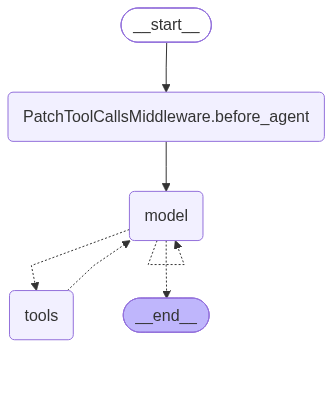

In [ ]:
from deepagents import create_deep_agent
agent=create_deep_agent(
    model="groq:openai/gpt-oss-120b",
    system_prompt=(
        "You are a research assistant specializing in scientific literature. "
        "Always cite sources. Use subagents for parallel research on different topics."
    ),
)

agent

### Invoke the Agent

In [3]:
result=agent.invoke({"messages": [{"role":"user", "content":"What is Deep Agent"}]})
result

{'messages': [HumanMessage(content='What is Deep Agent', additional_kwargs={}, response_metadata={}, id='f8ae5bb7-a59e-4f58-b336-8950fae8ed7a'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to answer: "What is Deep Agent". Likely a concept in AI? Could be "Deep Agent" as a term in reinforcement learning: deep reinforcement learning agents. Or "Deep Agent" might be a specific framework or library. Need to provide explanation, citations. Use literature. Use subagents to research.\n\nWe need to browse filesystem? The environment likely contains some docs. Let\'s search.', 'tool_calls': [{'id': 'fc_2adfa4e0-3e0a-42dd-8d74-8412f8dcc372', 'function': {'arguments': '{"path":"","pattern":"*deep*agent*"}', 'name': 'glob'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 114, 'prompt_tokens': 1933, 'total_tokens': 2047, 'completion_time': 0.235893385, 'completion_tokens_details': {'reasoning_tokens': 82}, 'prompt_time': 0.091454092, 'pro

### Context Engineering with `AGENTS.md`

Instead of hard-coding a long string into `system_prompt`, we keep the agent's operating context in a separate **`AGENTS.md`** file. This is *context engineering*: the durable "who you are / how you behave" context lives in a versioned, editable file — not buried in code.

In [5]:
from pathlib import Path
agents_md=Path("projects/AGENTS.md").read_text(encoding="utf-8")
agents_md

'# Agents.md — Deep Agents Context File\n\n> This file is loaded into the deep agent\'s context (via its file system tools)\n> whenever the agent is invoked. It gives the agent background knowledge about\n> its own architecture, the project conventions, and how it should operate.\n\n---\n\n## 1. What is a Deep Agent?\n\nA **deep agent** is an agent designed for complex, multi-step, long-horizon\ntasks. Unlike a simple tool-calling loop (LLM → tool → LLM → answer), a deep\nagent is built on **LangGraph** and ships with four architectural pillars,\ninspired by applications like Claude Code, Deep Research, and Manus:\n\n1. **Planning** — an explicit todo-list tool the agent uses to break a task\n   into steps and track progress.\n2. **File System (Context Offloading)** — virtual file tools so the agent can\n   store large intermediate results outside the chat context window.\n3. **Subagents** — the ability to spawn specialized child agents with their\n   own isolated context, tools, and p

---

## 2. Memory Saver
MemorySaver is a LangGraph checkpointer that stores conversation state in memory, allowing an agent to resume a conversation when the same thread ID is reused. Its checkpoints are not durable across process restarts.

### Initialize a Checkpointer with `MemorySaver`
MemorySaver stores checkpoints of the agent's state, allowing the agent to continue a conversation when the same thread ID is reused.

In [7]:
from langgraph.checkpoint.memory import MemorySaver
checkpointer=MemorySaver()

agent=create_deep_agent(
    model="groq:openai/gpt-oss-120b",
    checkpointer=MemorySaver(),
    # no backend, no memory, no files
)

### Pass Project Instructions to the Agent

In [8]:
result = agent.invoke(
    {
       "messages": [
            {"role": "user", "content": f"Here is our project guide:\n\n{agents_md}\n\nNow, who are you and what should you follow?"}
        ]
    },
    config={"configurable": {"thread_id": "default-demo-1"}},  # fresh thread => memory loads
)

print(result["messages"][-1].content)

I am a **deep‑agent** built on top of LangGraph, just as described in the `Agents.md` file you just shared.  

**What that means for me**

| Aspect | How I behave |
|--------|--------------|
| **Planning** | Before tackling any multi‑step request I will create a todo list with `write_todos`, marking each item as *pending*, *in_progress*, or *completed* and updating the list as I go. |
| **File‑system offloading** | Large pieces of information (research results, scraped pages, drafts, etc.) will be written to files with `write_file`/`edit_file` and only brief summaries will stay in the chat. I’ll read those files back with `read_file` whenever I need the details. |
| **Subagents** | If a sub‑task is self‑contained or would benefit from an isolated context (e.g., deep web research, complex data analysis), I’ll spawn a subagent via the `task` tool, give it a concise description, and incorporate only its final answer. |
| **System prompt** | I follow the detailed system prompt that accompa

---

## 3. Memory Management with Backends
Backends determine where an agent's files are stored and how they are accessed.

- **StateBackend:** Stores files in the agent's state for temporary working context.
- **StoreBackend:** Stores files in a LangGraph store, enabling shared access across threads when the same store and namespace are used.
- **FilesystemBackend:** Stores files on the local filesystem, making them accessible through filesystem tools.

### StateBackend — Agent State

#### Create a Deep Agent with StateBackend

In [9]:
# --- Default backend (no backend= passed) ---
# With no backend specified, files/memory live in the agent's in-state filesystem.
# Since there's no disk access, memory reads from state — so we seed AGENTS.md via
# files= on invoke. (Without seeding, memory would silently load nothing.)

agent=create_deep_agent(
    model="groq:openai/gpt-oss-120b",
    memory=["/projects/AGENTS.md"],
    checkpointer=MemorySaver(),
)

In [10]:
from deepagents.backends.utils import create_file_data
create_file_data(agents_md)

{'content': '# Agents.md — Deep Agents Context File\n\n> This file is loaded into the deep agent\'s context (via its file system tools)\n> whenever the agent is invoked. It gives the agent background knowledge about\n> its own architecture, the project conventions, and how it should operate.\n\n---\n\n## 1. What is a Deep Agent?\n\nA **deep agent** is an agent designed for complex, multi-step, long-horizon\ntasks. Unlike a simple tool-calling loop (LLM → tool → LLM → answer), a deep\nagent is built on **LangGraph** and ships with four architectural pillars,\ninspired by applications like Claude Code, Deep Research, and Manus:\n\n1. **Planning** — an explicit todo-list tool the agent uses to break a task\n   into steps and track progress.\n2. **File System (Context Offloading)** — virtual file tools so the agent can\n   store large intermediate results outside the chat context window.\n3. **Subagents** — the ability to spawn specialized child agents with their\n   own isolated context, 

#### Seed AGENTS.md into Agent State

In [11]:
result = agent.invoke(
    {
        "messages": [{"role": "user", "content": "What's in your memory? Who are you?"}],
        "files": {"/projects/AGENTS.md": create_file_data(agents_md)},  # seed the in-state file
    },
    config={"configurable": {"thread_id": "default-demo-1"}},  # fresh thread => memory loads
)
print(result["messages"][-1].content)

**What’s in my memory right now**

- **`/projects/AGENTS.md`** – a 125‑line document that describes the whole “deep‑agent” framework used in this project. It explains the four core pillars (Planning, File‑system off‑loading, Sub‑agents, and the detailed System Prompt), how the `write_todos`, file tools, and `task` sub‑agent tool work, and gives operating guidelines for me (plan first, off‑load aggressively, delegate wisely, keep this file as the authoritative source of my own architecture, and synthesize final answers from files/notes).

- **The memory‑guidelines** that were injected with the user request. They tell me:
  * Treat the contents of `<agent_memory>` (the AGENTS.md file) as reference material, not immutable system instructions.
  * Update my persistent memory (by editing files) whenever the user gives new preferences, feedback, or information that will be useful for future interactions.
  * Never store transient details, passwords, API keys, or anything that isn’t a lasting

### StoreBackend — Shared Memory Across Threads
Use StoreBackend to keep files in a LangGraph store so different threads can access the same stored context.

#### Create a Deep Agent with StoreBackend

In [12]:
# --- StoreBackend: persistent, cross-thread memory ---
# WHY: files/memory live in a LangGraph BaseStore, NOT in one conversation's state.
# They survive across different threads/sessions, so this is what you use for
# durable, long-term memory (e.g. per-user preferences the agent should recall
# next week). Here InMemoryStore is used for the demo; swap in a persistent store
# (e.g. Postgres) for real persistence.
from deepagents.backends.store import StoreBackend
from langgraph.store.memory import InMemoryStore

store = InMemoryStore()

# Seed durable memory into the store once. Namespace + key identify the file.
store.put(("memories",), "AGENTS.md", create_file_data(agents_md))

store_agent = create_deep_agent(
    model="groq:openai/gpt-oss-120b",
    backend=StoreBackend(store=store, namespace=lambda rt: ("memories",)),
    memory=["/projects/AGENTS.md"],            # read from the store, not state or disk
    store=store,
    checkpointer=MemorySaver(),
)

#### Read Memory Across Threads

In [13]:
# Note: no files= seeding needed — the store already holds it, and it would persist
# even if we started a brand-new thread or rebuilt the agent.
result = store_agent.invoke(
    {"messages": [{"role": "user", "content": "What's in your memory? Who are you?"}]},
    config={"configurable": {"thread_id": "store-demo-1"}},
)
print(result["messages"][-1].content)

I don’t have any stored memories at the moment—my `<agent_memory>` section is currently empty.  

**Who I am**

I’m an AI assistant built to help you with a wide range of tasks: answering questions, writing or editing code, searching files, running tools, and more. I can read, create, and modify files on the system, run searches, and even launch sub‑agents for complex, multi‑step work.  

If you ever want me to remember something (e.g., a preference, an email address, a coding style, etc.), just let me know and I’ll store it for future interactions.


In [14]:
result

{'messages': [HumanMessage(content="What's in your memory? Who are you?", additional_kwargs={}, response_metadata={}, id='fe6546ea-1d2c-4e69-b67e-479363e4aaad'),
  AIMessage(content='I don’t have any stored memories at the moment—my `<agent_memory>` section is currently empty.  \n\n**Who I am**\n\nI’m an AI assistant built to help you with a wide range of tasks: answering questions, writing or editing code, searching files, running tools, and more. I can read, create, and modify files on the system, run searches, and even launch sub‑agents for complex, multi‑step work.  \n\nIf you ever want me to remember something (e.g., a preference, an email address, a coding style, etc.), just let me know and I’ll store it for future interactions.', additional_kwargs={'reasoning_content': 'The user asks: "What\'s in your memory? Who are you?" We need to answer based on the memory content. The system gave us an empty <agent_memory>. So memory currently has nothing. We should respond: I have no store

### FilesystemBackend — Memory from Local Files
Use FilesystemBackend when the agent needs to read existing project instructions and files directly from disk.

#### Create a Deep Agent with FilesystemBackend

In [15]:
# --- FilesystemBackend: read files/memory straight from DISK ---
# WHY: the agent's files and memory map to real files on disk under root_dir.
# Nothing to seed — if AGENTS.md exists on disk, memory just loads it. Best for
# project context (AGENTS.md, docs, code) that already lives in your repo.
from deepagents.backends.filesystem import FilesystemBackend

# root_dir = the projects/ folder, so paths are resolved relative to it.
# AGENTS.md sits directly inside projects/, so the memory path is just "AGENTS.md".
# virtual_mode=True confines the agent to root_dir (blocks '..' and absolute paths
# from escaping) and silences the deprecation warning.
fs_agent = create_deep_agent(
    model="groq:openai/gpt-oss-120b",
    backend=FilesystemBackend(root_dir="projects", virtual_mode=True),
    memory=["AGENTS.md"],                             # -> projects/AGENTS.md
    checkpointer=MemorySaver(),
)

#### Load Memory from the Filesystem

In [16]:
# Fresh thread_id so MemoryMiddleware reloads (memory loads once per thread).
result = fs_agent.invoke(
    {"messages": [{"role": "user", "content": "What's in your memory? Who are you?"}]},
    config={"configurable": {"thread_id": "fs-demo-2"}},
)
print(result["messages"][-1].content)

**What’s in my memory right now**

At the moment the only file that has been loaded into my persistent memory is **`/AGENTS.md`**. It contains the full description of the “deep‑agent” architecture that I’m built on, including:

* The four core pillars – planning (todo list), file‑system off‑loading, sub‑agents, and the detailed system prompt.  
* How the planning tool (`write_todos`) works and why I should use it for multi‑step tasks.  
* How the virtual file tools (`ls`, `read_file`, `write_file`, `edit_file`) let me store large intermediate results outside the chat context.  
* How to spawn and interact with sub‑agents via the `task` tool.  
* Operating guidelines – plan first, offload aggressively, delegate wisely, treat this file as the authoritative source about my own behavior, and synthesize final answers from notes/files.

No other files or user‑specific data are currently present in my memory.

---

**Who am I?**

I am a **deep agent**—an autonomous, multi‑step AI assistant bu

In [17]:
result = fs_agent.invoke(
    {"messages": [{"role": "user", "content": "What is LLM Gateways?"}]},
    config={"configurable": {"thread_id": "fs-demo-2"}},
)
print(result["messages"][-1].content)

**LLM Gateways – an overview**

An **LLM Gateway** is a software layer (often offered as a hosted service or a self‑hosted component) that sits between a client application and one or more large‑language‑model (LLM) providers. Its purpose is to **unify, manage, and optimize access to LLM APIs** so developers don’t have to write bespoke integration code for every model they want to use.

### Why use a gateway?

| Need | How a gateway helps |
|------|----------------------|
| **Multi‑provider support** | Provides a single, consistent API (usually REST/HTTP or gRPC) that can route requests to OpenAI, Anthropic, Google Vertex, Cohere, etc., without the client needing to know each provider’s authentication, endpoint shape, or request format. |
| **Model selection & fallback** | Lets you specify a primary model and a fallback (e.g., “use `gpt‑4o` but fall back to `claude‑3‑sonnet` if the request fails or exceeds rate limits). |
| **Cost & performance optimization** | The gateway can automati

## Backend Comparison 
**Backends:** where the agent's files / memory live

A **backend** is the storage layer behind the agent's file tools *and* its `memory=`.
Same agent code, different durability:

| Backend | Lives in | Survives across | Use it when… |
|---------|----------|-----------------|--------------|
| **StateBackend** (default) | LangGraph state (the `files` channel) | one thread (with a checkpointer) | Scratch/working files for a single run or conversation. Ephemeral by design. |
| **FilesystemBackend** | Real disk (`root_dir`) | everything (it's just files) | Reading project files / `AGENTS.md` that already exist on disk. |
| **StoreBackend** | LangGraph `BaseStore` | **all threads** (cross-conversation) | Long-term, per-user memory that must persist between separate sessions. |

---

## 4. Skills

Skills are reusable agent capabilities that provide specialized workflows and domain knowledge. You can use Agent Skills to provide your deep agent with new capabilities and expertise. For ready-to-use skills that improve your agent’s performance on LangChain ecosystem tasks, see the LangChain Skills repository. Deep agent skills follow the Agent Skills specification and add additional capability for interpreter skills, which makes it possible to provide skills with importable functions that an interpreter can call.

### Setup and Imports
Import the required libraries and initialize the checkpointer and backend.

In [10]:
from deepagents import create_deep_agent
from deepagents.backends import StateBackend
from deepagents.backends.utils import create_file_data
from langgraph.checkpoint.memory import MemorySaver
from pathlib import Path

checkpointer = MemorySaver()
backend = StateBackend()

### Load a Single Skill
Read a skill's instructions from its SKILL.md file and prepare it for the agent's virtual filesystem.

In [11]:
skills_content= Path("skills/langgraph/SKILL.md").read_text(encoding="utf-8")

skills_files = {
    "/skills/langgraph/SKILL.md": create_file_data(skills_content),
}

### Load Multiple Skills
Load the available skills dynamically from their respective directories and map them to virtual filesystem paths.

In [12]:
# Read every skills/<name>/SKILL.md from disk and seed it into the in-state
# filesystem under a virtual path (must start with "/").
skill_dirs = ["langgraph", "python", "aws", "report-writer"]
skills_files = {
    f"/skills/{name}/SKILL.md": create_file_data(
        Path(f"skills/{name}/SKILL.md").read_text(encoding="utf-8")
    )
    for name in skill_dirs
}

In [13]:
skills_files

{'/skills/langgraph/SKILL.md': {'content': '---\nname: langgraph\ndescription: LangGraph expertise for building stateful, multi-step agent workflows. Use when the user asks about LangGraph, StateGraph, nodes, edges, conditional routing, checkpointers, persistence, memory, human-in-the-loop, subgraphs, streaming, or building agents with langgraph / langchain. Provides architecture patterns, API workflows, and runnable examples.\nlicense: MIT\nmetadata:\n  version: "1.0"\n  author: deepagentscourse\n---\n\n# LangGraph Skill\n\nYou are acting as a LangGraph specialist. Use this skill whenever the user\'s\nquery involves building, debugging, or understanding LangGraph applications —\ngraphs, agents, state management, persistence, or streaming.\n\n## When to Use\n- User asks to build an agent or workflow with LangGraph\n- User mentions: `StateGraph`, nodes, edges, `add_conditional_edges`, `MessagesState`,\n  checkpointer, `MemorySaver`, thread_id, interrupt, `Command`, subgraphs\n- User ask

### Create a Deep Agent with Skills
Initialize the Deep Agent and configure the /skills/ directory as the location from which it discovers available skills.

In [14]:
agent=create_deep_agent(
    model="groq:openai/gpt-oss-120b",
    backend=backend,
    skills=["/skills/"],
    checkpointer=checkpointer
)

### Discover Available Skills
Ask the agent to identify the available skills and explain when each one should be used.

In [15]:
result = agent.invoke(
    {
        "messages": [{"role": "user", "content": "What skills do you have available, and when would you use each?"}],
        
        "files": skills_files,
    },
    config={"configurable": {"thread_id": "skills-demo1"}},
)

print(result["messages"][-1].content)

**Available Skills**

| Skill | Domain / Focus | When to Use |
|-------|----------------|-------------|
| **aws** | Amazon Web Services (EC2, S3, Lambda, IAM, DynamoDB, RDS, ECS, EKS, CloudWatch, Bedrock, SageMaker, etc.) – architecture, cost‑optimization, security, boto3/CLI usage. | • The user asks how to provision, configure, or troubleshoot an AWS service.<br>• They need a reference architecture, IaC snippet, or cost‑saving advice.<br>• Questions about IAM policies, VPC design, serverless patterns, or migration strategies. |
| **langgraph** | LangGraph / LangChain state‑ful agent workflows – building graphs, nodes, edges, conditional routing, checkpoints, persistence, memory, sub‑graphs, streaming, human‑in‑the‑loop, etc. | • The user wants to design or debug a multi‑step agent.<br>• They need examples of `StateGraph`, custom nodes, or integration with LangChain tools.<br>• Guidance on persisting state, handling retries, or composing sub‑graphs. |
| **python** | Expert Python progr

In [16]:
result

{'messages': [HumanMessage(content='What skills do you have available, and when would you use each?', additional_kwargs={}, response_metadata={}, id='b60a8a21-bb11-47bd-85b9-e89123a33526'),
  AIMessage(content='**Available Skills**\n\n| Skill | Domain\u202f/\u202fFocus | When to Use |\n|-------|----------------|-------------|\n| **aws** | Amazon Web Services (EC2, S3, Lambda, IAM, DynamoDB, RDS, ECS, EKS, CloudWatch, Bedrock, SageMaker, etc.) – architecture, cost‑optimization, security, boto3/CLI usage. | • The user asks how to provision, configure, or troubleshoot an AWS service.<br>• They need a reference architecture, IaC snippet, or cost‑saving advice.<br>• Questions about IAM policies, VPC design, serverless patterns, or migration strategies. |\n| **langgraph** | LangGraph / LangChain state‑ful agent workflows – building graphs, nodes, edges, conditional routing, checkpoints, persistence, memory, sub‑graphs, streaming, human‑in‑the‑loop, etc. | • The user wants to design or debug 

### Test the LangGraph Skill
Ask a question related to LangGraph and inspect the conversation to see how the agent uses the relevant skill.

In [17]:
result = agent.invoke(
      {
          "messages": [{
              "role": "user",
              "content": "How do I build a LangGraph graph with conditional routing and memory? Show a minimal example.",       
          }],
          "files": skills_files,   # ✅  seed skills into THIS thread's state
      },
      config={"configurable": {"thread_id": "skills-demo-2"}},
  )

# Print the conversation so you can SEE the skill being triggered:
# look for a ToolMessage from `read_file` on the langgraph-docs SKILL.md.
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

How do I build a LangGraph graph with conditional routing and memory? Show a minimal example.
================================== Ai Message ==================================
Tool Calls:
  read_file (fc_8a980b6e-6c7d-4ecd-8073-b261fe58bc53)
 Call ID: fc_8a980b6e-6c7d-4ecd-8073-b261fe58bc53
  Args:
    file_path: /skills/langgraph/SKILL.md
    limit: 1000
================================= Tool Message =================================
Name: read_file

@@ lines 1-41 of 41 @@
---
name: langgraph
description: LangGraph expertise for building stateful, multi-step agent workflows. Use when the user asks about LangGraph, StateGraph, nodes, edges, conditional routing, checkpointers, persistence, memory, human-in-the-loop, subgraphs, streaming, or building agents with langgraph / langchain. Provides architecture patterns, API workflows, and runnable examples.
license: MIT
metadata:
  version: "1.0"
  author: deepa

### Test the AWS Skill
Ask the agent to perform a task related to AWS.

In [18]:
result = agent.invoke(
      {
          "messages": [{
              "role": "user",
              "content": "How do i set up an EC2 instance in AWS.",       
          }],
          "files": skills_files,   # ✅  seed skills into THIS thread's state
      },
      config={"configurable": {"thread_id": "skills-demo-3"}},
  )

# Print the conversation so you can SEE the skill being triggered:
# look for a ToolMessage from `read_file` on the langgraph-docs SKILL.md.
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

How do i set up an EC2 instance in AWS.
================================== Ai Message ==================================
Tool Calls:
  read_file (fc_86b12c8b-3e5c-4f07-8945-9c2ef795c91c)
 Call ID: fc_86b12c8b-3e5c-4f07-8945-9c2ef795c91c
  Args:
    file_path: /skills/aws/SKILL.md
    limit: 1000
================================= Tool Message =================================
Name: read_file

@@ lines 1-41 of 41 @@
---
name: aws
description: AWS cloud expertise. Use when the user asks about AWS services (EC2, S3, Lambda, IAM, DynamoDB, RDS, ECS, EKS, CloudWatch, Bedrock, SageMaker), architecture design on AWS, boto3 / AWS CLI usage, cost optimization, or cloud security best practices. Provides decision frameworks, CLI/boto3 workflows, and worked examples.
license: MIT
metadata:
  version: "1.0"
  author: deepagentscourse
---

# AWS Skill

You are acting as an AWS solutions architect. Use this skill wheneve

### Test the Python Skill
Ask the agent to solve a programming problem using the relevant skill.

In [19]:
result = agent.invoke(
      {
          "messages": [{
              "role": "user",
              "content": "write me a python code to do binary search",       
          }],
          "files": skills_files,   # ✅  seed skills into THIS thread's state
      },
      config={"configurable": {"thread_id": "skills-demo-4"}},
  )

# Print the conversation so you can SEE the skill being triggered:
# look for a ToolMessage from `read_file` on the langgraph-docs SKILL.md.
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

write me a python code to do binary search
================================== Ai Message ==================================
Tool Calls:
  read_file (fc_57d3e992-8c0e-46d0-b2d3-6f393c93e461)
 Call ID: fc_57d3e992-8c0e-46d0-b2d3-6f393c93e461
  Args:
    file_path: /skills/python/SKILL.md
    limit: 2000
================================= Tool Message =================================
Name: read_file

@@ lines 1-39 of 39 @@
---
name: python
description: Expert Python programming skill. Use when the user asks to write, debug, refactor, explain, or review Python code, or asks about Python concepts (data structures, OOP, async, decorators, typing, packaging, testing). Provides coding standards, step-by-step workflows, and worked examples.
license: MIT
metadata:
  version: "1.0"
  author: deepagentscourse
---

# Python Skill

You are acting as a senior Python engineer. Use this skill whenever the user's
query inv